In [1]:
# Parameters
D = "/n/lab_storage/eddy_lab/Lab/mckinley/data"
SAMAP = f"{D}/20261113_samap_final_ensembl_ids.h5ad"  # the SAMap object of record; read, never changed
HUMAN = f"{D}/20261113_Human_only_eFib_dec_final_nick.h5ad"
MOUSE = f"{D}/20261113_mouse_only_eFib_dec_final_nick.h5ad"
COLUMNS = ["pseudotime", "x_um_dbscan", "y_um_dbscan"]  # per nucleus, from its own species' object
OUT = f"{D}/20261113_samap_final_ensembl_ids_annotated.h5ad"  # a new file

In [2]:
import scanpy as sc

In [3]:
print("loading samap")
samap = sc.read_h5ad(SAMAP)
print("loading mouse")
mouse = sc.read_h5ad(MOUSE)
print("loading human")
human = sc.read_h5ad(HUMAN)

loading samap
loading mouse
loading human


In [4]:
import os

OUT = f"{D}/20261113_samap_final_ensembl_ids_pseudotime.h5ad"  # a new file
assert not os.path.exists(OUT), f"{OUT} exists"
samap.obs["mouse_pseudotime"] = mouse.obs["pseudotime"].reindex(samap.obs_names)
samap.obs["human_pseudotime"] = human.obs["pseudotime"].reindex(samap.obs_names)
print(samap.obs[["mouse_pseudotime", "human_pseudotime"]].notna().sum())  # expect 41,791 and 44,949

mouse_pseudotime    41791
human_pseudotime    44949
dtype: int64


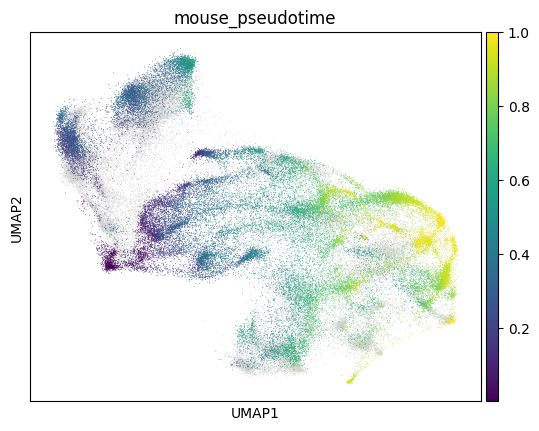

In [5]:
sc.pl.umap(samap, color = 'mouse_pseudotime')

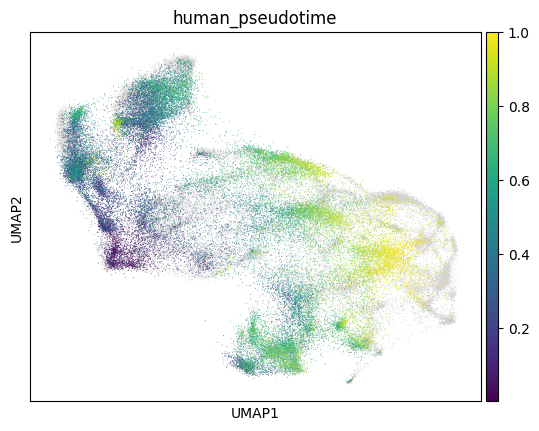

In [6]:
sc.pl.umap(samap, color = 'human_pseudotime')

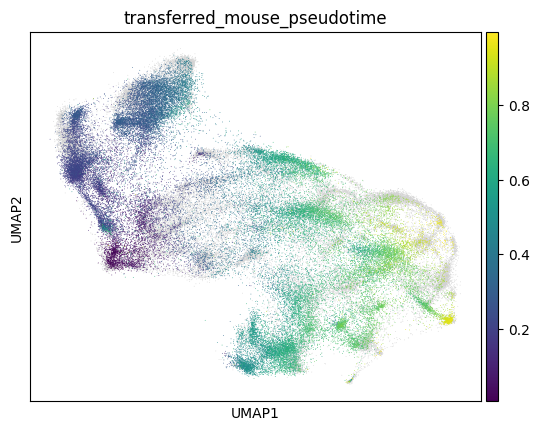

In [7]:
sc.pl.umap(samap, color = 'transferred_mouse_pseudotime')

In [8]:
samap.write_h5ad(OUT)

In [9]:
mouse

AnnData object with n_obs × n_vars = 42966 × 32287
    obs: 'sample', 'timepoint', 'n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'pct_counts_ribo', 'doubletdetection_predicted_doublet', 'doubletdetection_doublet_score', 'cell_barcode', 'x_um_dbscan', 'y_um_dbscan', 'cell_type', 'cell_subtype', 'pseudotime', 'Ulrich2024_sg_Stro7_top50_transferred'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'cell_subtype_colors', 'cell_type_colors', 'hvg', 'neighbors_scVI_100', 'sample_colors', 'timepoint_colors', 'umap'
    obsm: 'X_scVI', 'X_umap_scVI', 'spatial'
    layers: 'log1p_counts', 'raw_counts'
    obsp: 'neighbors_scVI_100_connectivities', 'neighbors_scVI_100_distances'

In [10]:
human

AnnData object with n_obs × n_vars = 46818 × 38606
    obs: 'sample', 'timepoint', 'n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'pct_counts_ribo', 'doubletdetection_predicted_doublet', 'doubletdetection_doublet_score', 'cell_barcode', 'x_um_dbscan', 'y_um_dbscan', 'cell_type', 'cell_subtype', 'old_cell_type', 'Ulrich2024_sg_Stro7_top50', 'pseudotime', 'transferred_mouse_fibdec', 'transferred_mouse_pseudotime'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'cell_subtype_colors', 'cell_type_colors', 'hvg', 'in_fib_and_smc_colors', 'neighbors_scVI_100', 'sample_colors', 'timepoint_colors', 'umap'
    obsm: 'X_scVI', 'X_umap_scVI', 'spatial', 'spatial_andy'
    layers: 'log1p_counts', 'raw_counts'
    obsp: 'neighbors_scVI_100_connectivities', 'neighbors_scVI_100_distances'

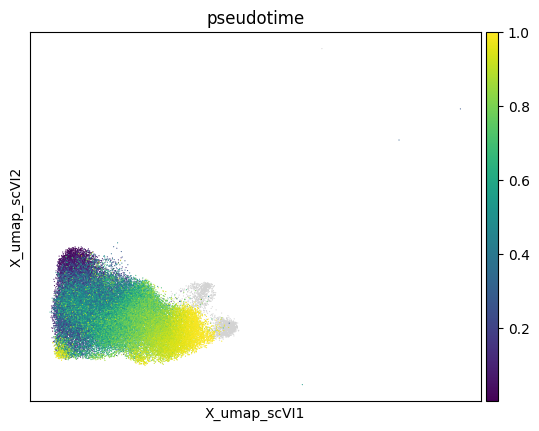

In [14]:
sc.pl.embedding(human, basis = 'X_umap_scVI', color = 'pseudotime')

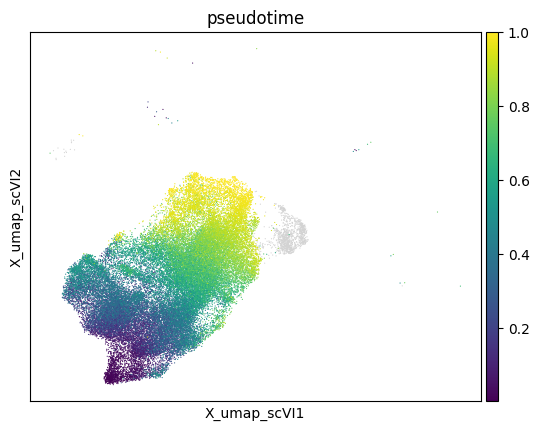

In [15]:
sc.pl.embedding(mouse, basis = 'X_umap_scVI', color = 'pseudotime')

human_pdt = sc.read_h5ad("/n/lab_storage/eddy_lab/Lab/mckinley/data/20261110_mouse_only_eFib_dec_final_nick_pdt.h5ad")

In [16]:
human_pdt = sc.read_h5ad("/n/lab_storage/eddy_lab/Lab/mckinley/data/20261110_mouse_only_eFib_dec_final_nick_pdt.h5ad")

In [17]:
mouse_pdt = sc.read_h5ad("/n/lab_storage/eddy_lab/Lab/mckinley/data/20261112_Human_fibdec_final_nick_pdt.h5ad")

In [18]:
temp = human_pdt.copy()

In [19]:
mouse_pdt = human_pdt.copy()

In [20]:
human_pdt = mouse_pdt.copy()

In [21]:
import os

del temp  # frees one of the three copies
mouse_pdt = sc.read_h5ad(f"{D}/20261110_mouse_only_eFib_dec_final_nick_pdt.h5ad")
human_pdt = sc.read_h5ad(f"{D}/20261112_Human_fibdec_final_nick_pdt.h5ad")

for adata, pdt, out in [(mouse, mouse_pdt, f"{D}/20261113_mouse_only_eFib_dec_final_nick_v2.h5ad"),
                        (human, human_pdt, f"{D}/20261113_Human_only_eFib_dec_final_nick_v2.h5ad")]:
    assert not os.path.exists(out), out
    assert adata.obs_names.equals(pdt.obs_names), out  # same nuclei, same order; fails if the objects are swapped
    adata.obsm["X_diffmap"] = pdt.obsm["X_diffmap"]
    adata.obsm["X_scVI_pseudotime"] = pdt.obsm["X_scVI_pseudotime"]
    adata.uns["pseudotime"] = pdt.uns["pseudotime"]  # root, root_label, diffmap_evals, n_dcs, method, inputs
    print(out, adata.uns["pseudotime"]["root_label"], adata.obsm_keys())
    adata.write_h5ad(out)

/tmp/ipykernel_1915124/1226407590.py:14: FutureWarning: The method obsm_keys is deprecated and will be removed in the future. Use obsm instead of obsm_keys. (e.g. `k in adata.obsm` or `adata.obsm.keys() | {'u'}`)
  print(out, adata.uns["pseudotime"]["root_label"], adata.obsm_keys())


/n/lab_storage/eddy_lab/Lab/mckinley/data/20261113_mouse_only_eFib_dec_final_nick_v2.h5ad eFib1 ['X_scVI', 'X_umap_scVI', 'spatial', 'X_diffmap', 'X_scVI_pseudotime']


/tmp/ipykernel_1915124/1226407590.py:14: FutureWarning: The method obsm_keys is deprecated and will be removed in the future. Use obsm instead of obsm_keys. (e.g. `k in adata.obsm` or `adata.obsm.keys() | {'u'}`)
  print(out, adata.uns["pseudotime"]["root_label"], adata.obsm_keys())


/n/lab_storage/eddy_lab/Lab/mckinley/data/20261113_Human_only_eFib_dec_final_nick_v2.h5ad eFib1 ['X_scVI', 'X_umap_scVI', 'spatial', 'spatial_andy', 'X_diffmap', 'X_scVI_pseudotime']


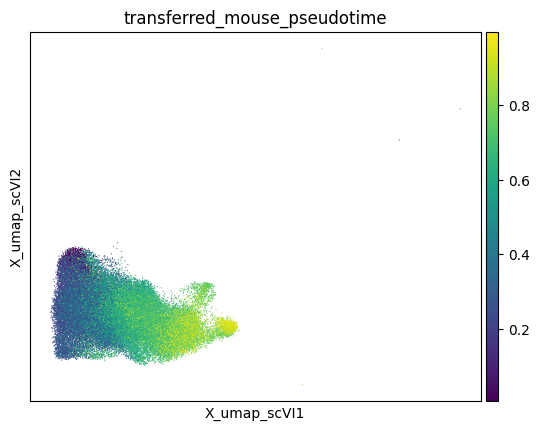

In [24]:
sc.pl.embedding(human, basis = 'X_umap_scVI', color = 'transferred_mouse_pseudotime')

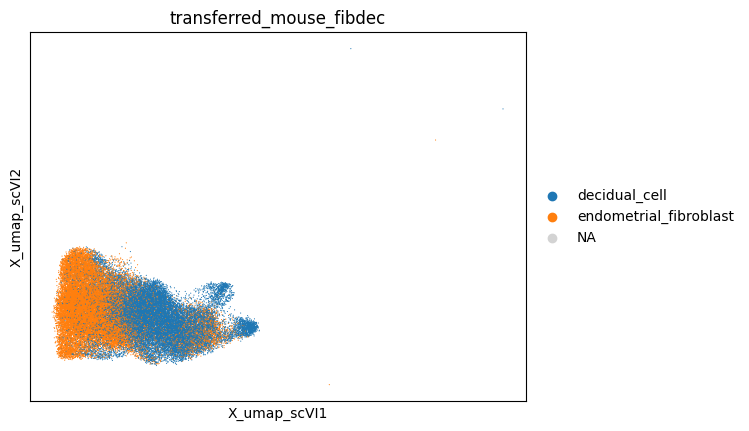

In [27]:
sc.pl.embedding(human, basis = 'X_umap_scVI', color = 'transferred_mouse_fibdec')

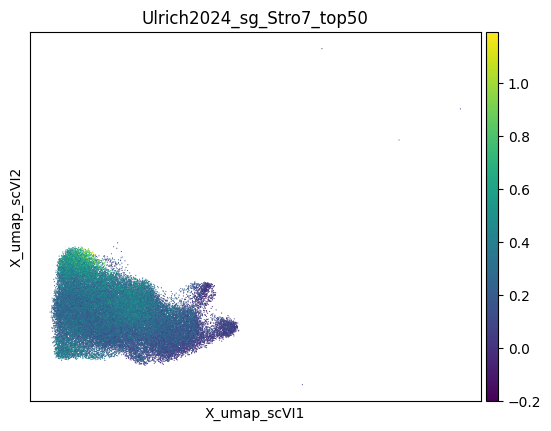

In [29]:
sc.pl.embedding(human, basis = 'X_umap_scVI', color = 'Ulrich2024_sg_Stro7_top50')

In [26]:
human

AnnData object with n_obs × n_vars = 46818 × 38606
    obs: 'sample', 'timepoint', 'n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'pct_counts_ribo', 'doubletdetection_predicted_doublet', 'doubletdetection_doublet_score', 'cell_barcode', 'x_um_dbscan', 'y_um_dbscan', 'cell_type', 'cell_subtype', 'old_cell_type', 'Ulrich2024_sg_Stro7_top50', 'pseudotime', 'transferred_mouse_fibdec', 'transferred_mouse_pseudotime'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'cell_subtype_colors', 'cell_type_colors', 'hvg', 'in_fib_and_smc_colors', 'neighbors_scVI_100', 'sample_colors', 'timepoint_colors', 'umap', 'pseudotime'
    obsm: 'X_scVI', 'X_umap_scVI', 'spatial', 'spatial_andy', 'X_diffmap', 'X_scVI_pseudotime'
    layers: 'log1p_counts', 'raw_counts'
    obsp: 'neighbors_scVI_100_connectivities', 'neighbors_scVI_100_distances'

In [30]:
mouse

AnnData object with n_obs × n_vars = 42966 × 32287
    obs: 'sample', 'timepoint', 'n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'pct_counts_ribo', 'doubletdetection_predicted_doublet', 'doubletdetection_doublet_score', 'cell_barcode', 'x_um_dbscan', 'y_um_dbscan', 'cell_type', 'cell_subtype', 'pseudotime', 'Ulrich2024_sg_Stro7_top50_transferred'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'cell_subtype_colors', 'cell_type_colors', 'hvg', 'neighbors_scVI_100', 'sample_colors', 'timepoint_colors', 'umap', 'pseudotime'
    obsm: 'X_scVI', 'X_umap_scVI', 'spatial', 'X_diffmap', 'X_scVI_pseudotime'
    layers: 'log1p_counts', 'raw_counts'
    obsp: 'neighbors_scVI_100_connectivities', 'neighbors_scVI_100_distances'